# 学習データを増やすと精度がどう変わるか調べる（学習曲線）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/12_classification/learning_curve.ipynb)

NLP クックブック 12-08 ／ テキスト分類

あと何件アノテーションすれば精度が上がるのか、もう頭打ちなのかを判断したい。

   50 件: macro-F1 = 0.343
  100 件: macro-F1 = 0.551
  200 件: macro-F1 = 0.719
  400 件: macro-F1 = 0.785
  800 件: macro-F1 = 0.837
 1600 件: macro-F1 = 0.861
 2800 件: macro-F1 = 0.879


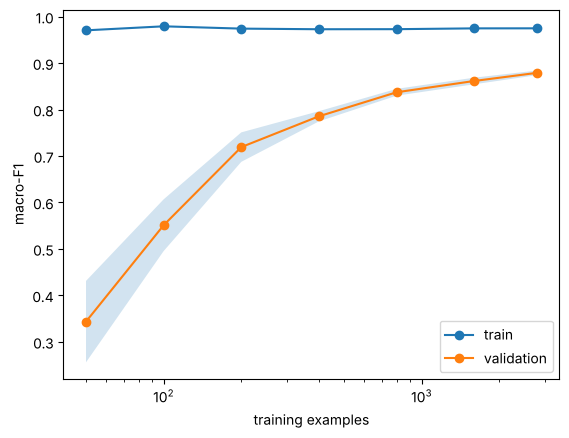

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedShuffleSplit, learning_curve
from sklearn.pipeline import make_pipeline

cats = ["rec.sport.baseball", "sci.space", "comp.graphics", "talk.politics.mideast", "rec.autos", "sci.med"]
data = fetch_20newsgroups(subset="train", categories=cats, remove=("headers", "footers", "quotes"))
pipe = make_pipeline(TfidfVectorizer(stop_words="english", sublinear_tf=True), LogisticRegression(C=10, max_iter=1000))

sizes, train_scores, val_scores = learning_curve(
    pipe, data.data, data.target, train_sizes=[50, 100, 200, 400, 800, 1600, 2800],
    cv=StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=0), scoring="f1_macro", n_jobs=-1)

for n, v in zip(sizes, val_scores.mean(axis=1)):
    print(f"{n:5} 件: macro-F1 = {v:.3f}")
plt.plot(sizes, train_scores.mean(axis=1), "o-", label="train")
plt.plot(sizes, val_scores.mean(axis=1), "o-", label="validation")
plt.fill_between(sizes, val_scores.mean(axis=1) - val_scores.std(axis=1), val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.2)
plt.xscale("log"); plt.xlabel("training examples"); plt.ylabel("macro-F1"); plt.legend(); plt.show()

- 横軸を対数にして直線的に伸びているなら、データを倍にすれば同じ幅だけ上がると期待できる。寝てきたら頭打ち。
- 学習データでのスコアと検証スコアの差が大きいのは過学習の印。データを増やすか、正則化を強める。